멀티 에이전트
- 에이전트에 노드를 추가하지 않고 따로 필요한 이유?
- 예) 사용할 수 있는 검색 엔진이 다수. 이를 별도의 에이전트에 담아 전문가 집단을 만드는 식

노드와 에이전트의 차이
- 노드: 그래프 안에서 실행 단위 하나. llm 포함할 수도 없이 함수일 수도.
- 에이전트: 목표를 가지고 실행 할 수 있는 시스템. 노드를 포함할 수 있는 전체적인 지능 시스템. 판단을 위해 무조건 llm이 필요

# **1. 멀티 에이전트**
- 단일 Agent가 조사, 분석, 작성, 검수까지 모두 맡으면 프롬프트가 복잡해지고, 실패 지점이나 책임을 구분하기 어려움
- 멀티 에이전트는 작업을 역할별로 나누고, 각 결과를 다음 담당자에게 전달
    - Network: 동료 간 상호 위임이 가능한 연결 구조
    - Supervisor: 여러 담당자의 순서를 결정하는 중앙 관리자
    - Hierarchical: 팀 안에 팀이 있는 계층적 조직

### HandOff
- 현재 담당자가 다른 담당자에게 실행 제어권을 넘기는 것

In [2]:
import matplotlib.pyplot as plt
import os, json

from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from langgraph.types import Command
from tavily import TavilyClient
from dotenv import load_dotenv
from pathlib import Path
from pydantic import BaseModel, Field

In [3]:
class HandOffState(TypedDict, total=False):
    request: str
    department: str
    answer: str

def triage(state: HandOffState):
    text = state["request"].lower()
    dept = 'coding' if any(k in text for k in ('파이썬','코드','python','for문')) else 'writing'
    return {'department':dept}

def coding(state: HandOffState):
    return {"answer":f"[코딩담당]{state['request']} > 예제: for x in [1,2,3]: print(x)"}

def writing(state: HandOffState):
    return {"answer": f"[글쓰기 담당] {state['request']} > 도입/본문/마무리로 구성하세요"}

def route_handoff(state:HandOffState): # 넘길 에이전트 선택
    return state['department']

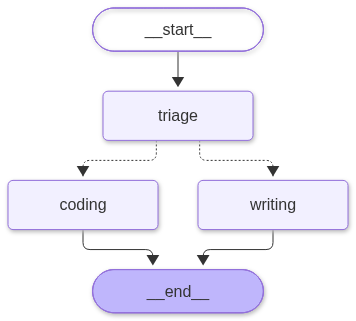

In [4]:
builder = StateGraph(HandOffState)
builder.add_node("triage", triage)
builder.add_node("coding", coding)
builder.add_node("writing", writing)
builder.add_edge(START,"triage")
builder.add_conditional_edges("triage", route_handoff, {"coding":"coding","writing":"writing"})
builder.add_edge("coding",END)
builder.add_edge("writing",END)
handoff_graph = builder.compile()
handoff_graph

In [5]:
for q in ["파이썬 for문 설명해줘", "감사 인사말을 작성해줘"]:
    print(handoff_graph.invoke({"request":q}))

{'request': '파이썬 for문 설명해줘', 'department': 'coding', 'answer': '[코딩담당]파이썬 for문 설명해줘 > 예제: for x in [1,2,3]: print(x)'}
{'request': '감사 인사말을 작성해줘', 'department': 'writing', 'answer': '[글쓰기 담당] 감사 인사말을 작성해줘 > 도입/본문/마무리로 구성하세요'}


In [6]:
for update in handoff_graph.stream({'request':'파이썬 리스트 예제'}, stream_mode="updates"):
    print(update)

{'triage': {'department': 'coding'}}
{'coding': {'answer': '[코딩담당]파이썬 리스트 예제 > 예제: for x in [1,2,3]: print(x)'}}


In [ ]:
llm = ChatOpenAI(model='gpt-5.6-luna', temperature=0)

# 1. 분류 에이전트
def triage(state: HandOffState) -> Command[Literal["coding","writing"]]:
    text = state["request"].lower()
    dept = 'coding' if any(k in text for k in ('파이썬','코드','python','for문')) else 'writing'
    # updates: 공유 상태(State)에 department 값을 저장. got: 다음에 실행할 노드를 지정
    return Command(update={'department':dept}, goto=dept) # Command로 다른 노드에 상태 전달

# 2. 코딩 에이전트
def coding(state: HandOffState):
    response = llm.invoke(
        f"당신은 파이썬 전문 강사입니다. 쉽게 설명하세요. \n질문: {state['request']}"
    )
    return {"answer": response.content}

# 3. 글쓰기 에이전트
def writing(state: HandOffState):
    response = llm.invoke(
        f"당신은 전문 작가입니다. 자연스럽게 글을 작성하세요.\n요청: {state['request']}"
    )
    return {"answer": response.content}

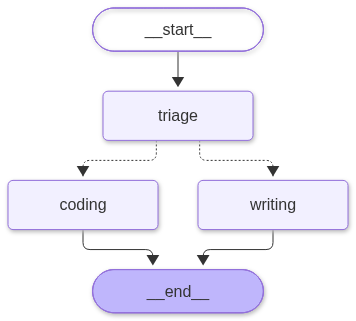

In [11]:
builder = StateGraph(HandOffState)
builder.add_node("triage",triage)
builder.add_node("coding",coding)
builder.add_node("writing",writing)
builder.add_edge(START, "triage")
builder.add_edge("coding",END)
builder.add_edge("writing",END)
graph = builder.compile()
graph

In [12]:
for q in ["파이썬 for문 설명해줘", "감사 인사말을 작성해줘"]:
    result = graph.invoke({"request":q})
    print(f'\n질문: {q}')
    print(f"담당: {result["department"]}")
    print(f"답변: {result["answer"]}")


질문: 파이썬 for문 설명해줘
담당: coding
답변: 파이썬의 `for`문은 **여러 개의 데이터를 하나씩 꺼내서 반복 처리할 때** 사용합니다.

## 1. 기본 형태

```python
for 변수 in 반복할_데이터:
    실행할_문장
```

예를 들어 리스트의 값을 하나씩 출력할 수 있습니다.

```python
fruits = ["사과", "바나나", "딸기"]

for fruit in fruits:
    print(fruit)
```

실행 결과:

```text
사과
바나나
딸기
```

동작 방식은 다음과 같습니다.

1. `fruits`에서 `"사과"`를 꺼냅니다.
2. `fruit` 변수에 저장합니다.
3. `print(fruit)`를 실행합니다.
4. 다음 값인 `"바나나"`, `"딸기"`도 같은 방식으로 처리합니다.

---

## 2. 숫자를 반복할 때: `range()`

`range()`는 일정한 범위의 숫자를 만들어 줍니다.

```python
for i in range(5):
    print(i)
```

결과:

```text
0
1
2
3
4
```

`range(5)`는 **0부터 5보다 작은 숫자까지**를 의미합니다.

### 1부터 5까지 출력하기

```python
for i in range(1, 6):
    print(i)
```

결과:

```text
1
2
3
4
5
```

형식은 다음과 같습니다.

```python
range(시작값, 끝값)
```

단, `끝값`은 포함되지 않습니다.

---

## 3. 반복하면서 계산하기

```python
for i in range(1, 6):
    print(i * 2)
```

결과:

```text
2
4
6
8
10
```

---

## 4. 문자열도 반복할 수 있습니다

문자열의 글자를 하나씩 꺼낼 수 있습니다.

```python
word = "Python"

for letter in word:
    print(letter)
```

결

### 1. Network
각 전문 에이전트로 되어 있으며 직접 이웃 에이전트로 handoff를 함 (직접 연결된 형태)

In [6]:
load_dotenv()

True

In [7]:
if not os.getenv('OPENAI_API_KEY'):
    raise RuntimeError(".env에 openai api key 설정!")
llm = ChatOpenAI(model=os.getenv("OPENAI_MODEL", "gpt-5.6-luna"), temperature=0)

In [11]:
OUTPUT_DIR = Path("multi_agent_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

In [8]:
def ask(system: str, user: str) -> str:
    """
    시스템 지시와 사용자 입력을 구분해 LLM을 호출합니다.
    """# LLM이 노드 실행 시 설명을 읽을 수 있으니 적는게 좋음

    response = llm.invoke([("system", system), ("human",user)])
    return str(response.content)

In [15]:
class ChartState(TypedDict, total=False):
    question: str
    sources: list[dict]
    data: list[dict]
    summary: str
    chart_path: str
    error: str

class ChartData(TypedDict):
    label: str
    value: float

In [13]:
def search_web(query: str) -> list[dict]:
    key = os.getenv("TAVILY_API_KEY")
    if not key:
        raise RuntimeError("TAVILY KEY ERROR!")
    result = TavilyClient(api_key=key).search(query=query, max_results=5)
    return [{"title": x.get("title",""), "url": x.get("url",""), "content": x.get("content","")[:1500]} for x in result.get("results",[])]

In [16]:
class ResearchData(BaseModel):
    data: list[ChartData] = Field(description="출처에서 확인된 수치만")
    summary: str

In [18]:
research_llm = llm.with_structured_output(ResearchData)

In [ ]:
def researcher(state: ChartState) -> Command[Literal["chart","__end__"]]:
    sources = search_web(state['question'])
    parsed = research_llm.invoke([
        ("system","검색 결과에 명시된 값만 추출하세요. 추정하거나 없는 수치를 생성하지 마세요. 각 수치의 단위가 일관되어야 합니다. 확인 불가능하면 data를 빈 목록으로 반환하세요."),
        ("human", json.dumps({"question": state["question"], "sources":sources}, ensure_ascii=False))
    ])
    if not parsed.data:
        return Command(update={"sources":sources, "error": "검증 가능한 수치가 없습니다."},
                goto=END)
    return Command(update={"sources": sources, "data": [x.model_dump() if hasattr(x,"model_dump") else x for x in parsed.data], "summary":parsed.summary}, goto='chart')


In [21]:
def chart(state: ChartState) -> Command[Literal["__end__"]]:
    rows = state["data"]
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar([r["label"] for r in rows], [r["value"] for r in rows])
    ax.set_title("Research results (verify units and sources)")
    ax.tick_params(axis="x", rotation=25)
    fig.tight_layout()
    path = OUTPUT_DIR / "research_chart.png"
    fig.savefig(path, dpi=140)
    plt.show()
    plt.close(fig)
    return Command(update={"chart_path":str(path)}, goto=END)

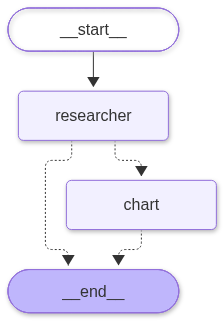

In [23]:
#에이전트끼리 엣지로 연결할 필요가 없어 간단해짐
builder = StateGraph(ChartState)
builder.add_node("researcher", researcher)
builder.add_node("chart",chart)
builder.add_edge(START, "researcher") # 에이전트에서 종료를 end로 처리해 여기에 end 필요없음
network_chart = builder.compile()
network_chart

In [27]:
plt.rcParams['font.family'] = 'Malgun Gothic'

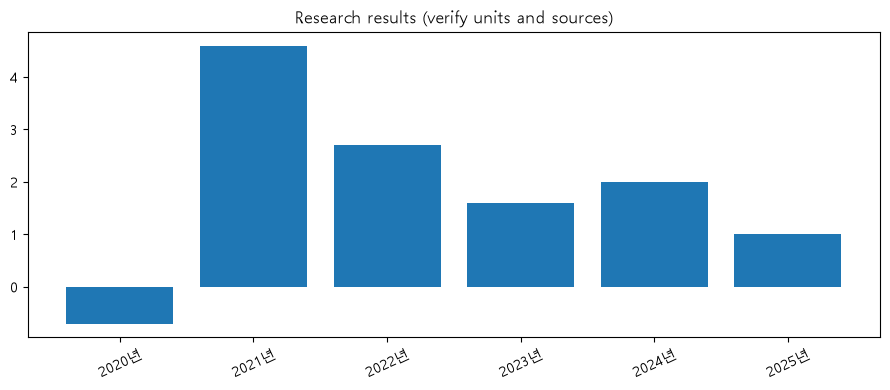

In [28]:
result = network_chart.invoke({"question":"2020년부터 2025년까지 한국의 연도별 실질 GDP 성장률(%)"}, config={"recursion_limit":5})

### 멀티 에이전트 기반(네트워크) AI 맞춤형 학습 진단 및 문제 출제 시스템
학생의 과목별 학습 점수를 분석하여 가장 취약한 학습 영역을 찾아내고, 해당 영역에 대한 맞춤형 문제를 자동으로 출제하는 AI 학습 진단 멀티 에이전트 시스템을 개발

- Diagnosis Agent: 학생의 영역별 점수를 분석하고 가장 취약한 영역을 찾아 학습 진단 결과를 작성
- Quiz Agent: 진단 결과를 전달받아 취약 영역에 대한 객관식 문제를 생성

```
scores = {"파이썬 기초문법": 90, "데이터 분석": 75, "딥러닝": 60}

1. 학생의 학습 점수를 입력받음
2. 모든 점수가 0~100점 사이인지 검사
3. 가장 점수가 낮은 학습 영역을 찾음
4. LLM을 이용하여 학생의 학습 상태를 3문장으로 진단
5. 진단 결과를 문제 출제 에이전트에게 전달
6. LLM을 이용하여 취약 영역에 대한 객관식 문제 3개를 생성
7. 각 문제에 정답과 해설을 포함
8. 최종 진단 결과와 생성된 문제를 출력
```

In [3]:
class StudyState(TypedDict,total=False):
    scores: dict[str,int]
    weakness: str
    diagnosis: str
    quiz: list[dict]

def diagnosis(state:StudyState)->Command[Literal['quiz']]:
    scores = state['scores']
    if not scores or any (not 0 <= v <= 100 for v in scores.values()):
        raise ValueError('영역별 점수를 0 ~ 100 사이로 입력하세요.')
    weak = min(scores, key=scores.get)
    explanation = ask("당신은 친절한 학습 진단 전문가입니다. 점수의 의미를 과장하지 말고 3문장으로 분석하세요.", f"영역별 점수: {scores}, 최저 영역:{weak}")

    return Command(update={'weakness':weak, 'diagnosis':explanation},goto='quiz')

def quiz(state:StudyState)->Command[Literal['__end__']]:
    content = ask('당신은 학습문제 출제 전문가입니다. 지정된 취약 영역에 대해 객관식 3문제를 만들고 각 문항에 정답과 쉬운 해설을 붙이세요. 애매한 문항은 피하세요.', f"취약 영역:{state['weakness']}\n진단: {state['diagnosis']}")
    return Command(update={'quiz':content},goto=END)

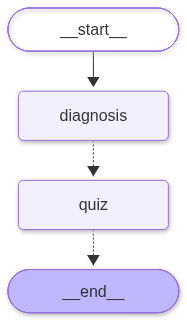

In [4]:
builder = StateGraph(StudyState)
builder.add_node("diagnosis",diagnosis)
builder.add_node("quiz",quiz)
builder.add_edge(START,"diagnosis")
study_network = builder.compile()
study_network

In [9]:
result = study_network.invoke({"scores":{"파이썬 기초문법": 90, "데이터 분석": 75, "딥러닝": 60}}, config={'recursion_limit':5})

In [10]:
print('[진단]',result['diagnosis'],'\n[문제]',result['quiz'])

[진단] 파이썬 기초문법은 90점으로 기본 문법 활용 능력이 비교적 안정적이며, 데이터 분석은 75점으로 핵심 개념을 이해하고 있으나 추가 연습이 필요해 보입니다.  
딥러닝은 60점으로 다른 영역보다 보완이 필요하지만, 점수만으로 학습 능력을 단정하기보다는 기초 수학·모델 구조·실습 경험 중 어느 부분이 어려운지 확인하는 것이 좋습니다.  
우선 신경망의 기본 개념과 간단한 예제 구현을 반복하고, 데이터 분석에서 익힌 전처리·시각화 능력을 딥러닝 실습에 연결해 보세요. 
[문제] ## 딥러닝 객관식 문제 3문항

### 1번. 신경망의 기본 구조
다음 중 인공 신경망에서 **가중치(weight)**의 역할로 가장 알맞은 것은 무엇인가요?

① 입력 데이터의 개수를 자동으로 늘린다.  
② 각 입력값이 결과에 미치는 영향의 크기를 조절한다.  
③ 학습 데이터를 정답 데이터로 변환한다.  
④ 손실 함수의 종류를 결정한다.  

**정답: ②**

**해설:**  
가중치는 각 입력값에 곱해져 결과에 미치는 영향의 크기를 조절합니다. 신경망은 학습 과정에서 가중치를 조금씩 수정하며 예측 성능을 높입니다.

---

### 2번. 활성화 함수 계산
ReLU 함수는 다음과 같이 정의됩니다.

\[
\text{ReLU}(x)=\max(0,x)
\]

입력값이 `-3`, `0`, `5`일 때 각각의 ReLU 출력으로 올바른 것은 무엇인가요?

① `-3, 0, 5`  
② `0, 0, 5`  
③ `0, 5, 5`  
④ `3, 0, -5`  

**정답: ②**

**해설:**  
ReLU는 음수를 모두 `0`으로 바꾸고, 양수는 그대로 출력합니다. 따라서 `-3 → 0`, `0 → 0`, `5 → 5`입니다.

---

### 3번. 신경망 학습 과정
신경망 학습에서 **역전파(backpropagation)**의 주요 역할은 무엇인가요?

① 입력 데이터를 무작위로 섞는 것  
② 예측값과 실제값의 차이를 이용해 가중치의 기울기를 계산하는 것  
③ 이미지의 크기